# Лабораторная работа №3

## Выполнил: Булавинов Даниил Сергеевич Б9124-01.03.02ИИ
## Исследование архитектуры информационно-поисковой системы на примере поиска по коллекции документов

**Темы коллекции:** автомобильная тематика и медицина.

In [1]:
import re
import copy
from collections import defaultdict

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML, display

pd.set_option("display.max_colwidth", None)

"""Красивый вывод таблицы без индекса строк."""
def show_table(df):
    display(HTML(df.to_html(index=False)))

"""Сортировка идентификаторов Д1, Д2, ..., Д10 по числу."""
def sort_ids(ids):
    return sorted(ids, key=lambda d: int(d[1:]))

"""Идентификаторы текстов где встретилось конкретное слово."""
def fmt(ids):
    ids = sort_ids(ids)
    return ", ".join(ids) if ids else "— (пусто)"

## 1. Коллекция документов

8 документов по двум темам (Д1–Д4 — автомобили, Д5–Д8 — медицина). В каждом 3–5 предложений, у каждого уникальный идентификатор. Ряд слов специально повторяется в разных документах (*расход*, *водитель*, *врач*, *пациента*, *риск*, *давление* и др.).

In [2]:
DOCS = {
    "Д1": "Двигатель автомобиля преобразует энергию топлива в механическую работу. "
          "Современный двигатель оснащён системой впрыска, которая точно дозирует топливо. "
          "Регулярная замена масла продлевает срок службы двигателя. "
          "Расход топлива зависит от стиля вождения.",

    "Д2": "Тормозная система автомобиля обеспечивает безопасность водителя и пассажиров. "
          "Тормозные колодки и диски со временем изнашиваются и требуют замены. "
          "Водитель должен регулярно проверять уровень тормозной жидкости. "
          "Неисправная тормозная система повышает риск аварии.",

    "Д3": "Электромобиль использует аккумулятор вместо двигателя внутреннего сгорания. "
          "Запас хода электромобиля зависит от ёмкости аккумулятора и стиля вождения. "
          "Зарядка аккумулятора занимает от тридцати минут до нескольких часов. "
          "Расход энергии снижается при плавном торможении.",

    "Д4": "Шины влияют на безопасность и расход топлива автомобиля. "
          "Водитель должен проверять давление в шинах каждый месяц. "
          "Зимой необходима замена летних шин на зимние. "
          "Изношенные шины увеличивают тормозной путь.",

    "Д5": "Врач назначает лечение после осмотра пациента и анализа результатов обследования. "
          "Регулярный осмотр помогает выявить заболевание на ранней стадии. "
          "Пациент должен точно соблюдать рекомендации врача. "
          "Своевременное лечение повышает шансы на выздоровление.",

    "Д6": "Антибиотики применяются для лечения бактериальных инфекций. "
          "Врач определяет дозировку лекарства с учётом возраста и веса пациента. "
          "Неправильный приём антибиотиков снижает эффективность лечения. "
          "Лекарство нужно принимать строго по назначению врача.",

    "Д7": "Вакцинация защищает организм от опасных инфекций. "
          "Вакцина формирует иммунитет и не вызывает тяжёлое заболевание. "
          "Врач проверяет состояние пациента перед вакцинацией. "
          "Регулярная вакцинация снижает риск эпидемий.",

    "Д8": "Высокое давление повышает риск инфаркта и инсульта. "
          "Пациент должен регулярно измерять давление и записывать результаты. "
          "Врач подбирает лекарство для снижения давления. "
          "Здоровое питание и физическая активность помогают контролировать давление.",
}

TOPICS = {d: ("Автомобили" if int(d[1:]) <= 4 else "Медицина") for d in DOCS}


def count_sentences(text):
    return len([s for s in re.split(r"(?<=[.!?])\s+", text.strip()) if s])


rows = []
for d, t in DOCS.items():
    n = count_sentences(t)
    assert 3 <= n <= 5, f"{d}: {n} предложений"
    rows.append({"ID": d, "Тема": TOPICS[d], "Предложений": n, "Текст": t})

show_table(pd.DataFrame(rows))

ID,Тема,Предложений,Текст
Д1,Автомобили,4,"Двигатель автомобиля преобразует энергию топлива в механическую работу. Современный двигатель оснащён системой впрыска, которая точно дозирует топливо. Регулярная замена масла продлевает срок службы двигателя. Расход топлива зависит от стиля вождения."
Д2,Автомобили,4,Тормозная система автомобиля обеспечивает безопасность водителя и пассажиров. Тормозные колодки и диски со временем изнашиваются и требуют замены. Водитель должен регулярно проверять уровень тормозной жидкости. Неисправная тормозная система повышает риск аварии.
Д3,Автомобили,4,Электромобиль использует аккумулятор вместо двигателя внутреннего сгорания. Запас хода электромобиля зависит от ёмкости аккумулятора и стиля вождения. Зарядка аккумулятора занимает от тридцати минут до нескольких часов. Расход энергии снижается при плавном торможении.
Д4,Автомобили,4,Шины влияют на безопасность и расход топлива автомобиля. Водитель должен проверять давление в шинах каждый месяц. Зимой необходима замена летних шин на зимние. Изношенные шины увеличивают тормозной путь.
Д5,Медицина,4,Врач назначает лечение после осмотра пациента и анализа результатов обследования. Регулярный осмотр помогает выявить заболевание на ранней стадии. Пациент должен точно соблюдать рекомендации врача. Своевременное лечение повышает шансы на выздоровление.
Д6,Медицина,4,Антибиотики применяются для лечения бактериальных инфекций. Врач определяет дозировку лекарства с учётом возраста и веса пациента. Неправильный приём антибиотиков снижает эффективность лечения. Лекарство нужно принимать строго по назначению врача.
Д7,Медицина,4,Вакцинация защищает организм от опасных инфекций. Вакцина формирует иммунитет и не вызывает тяжёлое заболевание. Врач проверяет состояние пациента перед вакцинацией. Регулярная вакцинация снижает риск эпидемий.
Д8,Медицина,4,Высокое давление повышает риск инфаркта и инсульта. Пациент должен регулярно измерять давление и записывать результаты. Врач подбирает лекарство для снижения давления. Здоровое питание и физическая активность помогают контролировать давление.


## 2. Предварительная обработка

Шаги: приведение к нижнему регистру → удаление знаков препинания → разбиение на слова → удаление служебных слов.

**Выбор служебных слов (стоп-слов).** В список включены предлоги, союзы и частицы: *и, в, на, с, по, от, до, для, при, без, за, перед, поэтому, не, или, что, а, к, из*. Причины:

- они не несут предметного смысла;
- они встречаются почти в каждом документе, поэтому их списки в индексе содержат почти всю коллекцию;
- удаление уменьшает размер индекса и ускоряет обработку запросов.

In [3]:
STOP_WORDS = {"и", "в", "на", "с", "по", "от", "до", "для", "при", "без",
              "за", "перед", "поэтому", "не", "или", "что", "а", "к", "из"}

def tokenize(text):
    text = text.lower()
    text = re.sub(r"[^\w\s]", " ", text)
    return text.split()

def preprocess(text, remove_stop=True):
    tokens = tokenize(text)
    if remove_stop:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    return tokens


# --- пример до и после обработки на документе Д1
sample = DOCS["Д1"]
step_lower = sample.lower()
step_nopunct = re.sub(r"[^\w\s]", " ", step_lower)
step_tokens = step_nopunct.split()
step_clean = [t for t in step_tokens if t not in STOP_WORDS]

print("ДО обработки:")
print(sample)
print("\n1) нижний регистр:")
print(step_lower)
print("\n2) без знаков препинания:")
print(" ".join(step_nopunct.split()))
print("\n3) список слов:")
print(step_tokens)
print("\n4) после удаления служебных слов:")
print(step_clean)

ДО обработки:
Двигатель автомобиля преобразует энергию топлива в механическую работу. Современный двигатель оснащён системой впрыска, которая точно дозирует топливо. Регулярная замена масла продлевает срок службы двигателя. Расход топлива зависит от стиля вождения.

1) нижний регистр:
двигатель автомобиля преобразует энергию топлива в механическую работу. современный двигатель оснащён системой впрыска, которая точно дозирует топливо. регулярная замена масла продлевает срок службы двигателя. расход топлива зависит от стиля вождения.

2) без знаков препинания:
двигатель автомобиля преобразует энергию топлива в механическую работу современный двигатель оснащён системой впрыска которая точно дозирует топливо регулярная замена масла продлевает срок службы двигателя расход топлива зависит от стиля вождения

3) список слов:
['двигатель', 'автомобиля', 'преобразует', 'энергию', 'топлива', 'в', 'механическую', 'работу', 'современный', 'двигатель', 'оснащён', 'системой', 'впрыска', 'которая', 'т

## 3. Инвертированный индекс

Индексатор проходит по всем документам, обрабатывает текст и для каждого слова запоминает множество идентификаторов документов, где оно встречается.

In [4]:
"""Инвертированный индекс: слово -> множество идентификаторов документов."""
def build_index(docs):
    index = defaultdict(set)
    for doc_id, text in docs.items():
        for term in preprocess(text):
            index[term].add(doc_id)
    return index

INDEX = build_index(DOCS)

"""19 содержательных слов коллекции"""
INDEX_TERMS = sorted([
    "автомобиля", "безопасность", "вождения", "водитель", "врач", "давление",
    "заболевание", "замена", "инфекций", "лекарство", "пациента", "повышает",
    "проверять", "расход", "регулярно", "риск", "снижает", "стиля", "топлива",
])

show_table(pd.DataFrame({
    "Слово": INDEX_TERMS,
    "Идентификаторы документов": [fmt(INDEX[t]) for t in INDEX_TERMS],
}))

Слово,Идентификаторы документов
автомобиля,"Д1, Д2, Д4"
безопасность,"Д2, Д4"
водитель,"Д2, Д4"
вождения,"Д1, Д3"
врач,"Д5, Д6, Д7, Д8"
давление,"Д4, Д8"
заболевание,"Д5, Д7"
замена,"Д1, Д4"
инфекций,"Д6, Д7"
лекарство,"Д6, Д8"


## 4. Запросы к индексу

Модуль обработки запросов:

1. применяет к запросу ту же предобработку, что и к документам;
2. для каждого слова извлекает из индекса список документов;
3. для **AND** берёт пересечение списков, для **OR** — объединение;
4. по идентификаторам из результата выдаёт полные тексты документов.

Запросы: два однословных (**давление**, **врач**) и два двухсловных (**расход вождения**, **риск снижает**), последние выполняются в режимах AND и OR.

In [5]:
"""Поиск по инвертированному индексу. Возвращает отсортированный список идентификаторов."""
def search(query, mode="AND", index=None, docs=None, verbose=True):
    index = INDEX if index is None else index
    docs = DOCS if docs is None else docs

    terms = preprocess(query)
    postings = [set(index.get(t, set())) for t in terms]

    if len(terms) == 1:
        result, op_text = postings[0], "один термин — результат равен его списку"
    elif mode.upper() == "AND":
        result = set.intersection(*postings)
        op_text = "пересечение (AND): " + " ∩ ".join("{" + fmt(p) + "}" for p in postings)
    else:
        result = set.union(*postings)
        op_text = "объединение (OR): " + " ∪ ".join("{" + fmt(p) + "}" for p in postings)

    if verbose:
        label = "один термин" if len(terms) == 1 else mode.upper()
        print(f"Запрос: «{query}»   режим: {label}")
        print(f"Термины после предобработки: {terms}")
        for t, p in zip(terms, postings):
            print(f"  индекс[{t!r}] = {fmt(p)}")
        print(f"  Операция: {op_text}")
        print(f"  ИТОГ: {fmt(result)}")
        for d in sort_ids(result):
            print(f"    {d}: {docs[d]}")
        print()
    return sort_ids(result)


print("=" * 90)
print("ЗАПРОС 1 (однословный)")
print("=" * 90)
r1 = search("давление")

print("=" * 90)
print("ЗАПРОС 2 (однословный)")
print("=" * 90)
r2 = search("врач")

print("=" * 90)
print("ЗАПРОС 3 (два слова): «расход вождения»")
print("=" * 90)
r3_and = search("расход вождения", mode="AND")
r3_or = search("расход вождения", mode="OR")

print("=" * 90)
print("ЗАПРОС 4 (два слова): «риск снижает»")
print("=" * 90)
r4_and = search("риск снижает", mode="AND")
r4_or = search("риск снижает", mode="OR")

ЗАПРОС 1 (однословный)
Запрос: «давление»   режим: один термин
Термины после предобработки: ['давление']
  индекс['давление'] = Д4, Д8
  Операция: один термин — результат равен его списку
  ИТОГ: Д4, Д8
    Д4: Шины влияют на безопасность и расход топлива автомобиля. Водитель должен проверять давление в шинах каждый месяц. Зимой необходима замена летних шин на зимние. Изношенные шины увеличивают тормозной путь.
    Д8: Высокое давление повышает риск инфаркта и инсульта. Пациент должен регулярно измерять давление и записывать результаты. Врач подбирает лекарство для снижения давления. Здоровое питание и физическая активность помогают контролировать давление.

ЗАПРОС 2 (однословный)
Запрос: «врач»   режим: один термин
Термины после предобработки: ['врач']
  индекс['врач'] = Д5, Д6, Д7, Д8
  Операция: один термин — результат равен его списку
  ИТОГ: Д5, Д6, Д7, Д8
    Д5: Врач назначает лечение после осмотра пациента и анализа результатов обследования. Регулярный осмотр помогает выявить з

**Сводка по запросам:**

| № | Запрос | Режим | Результат |
|---|--------|-------|-----------|
| 1 | давление | — | Д4, Д8 |
| 2 | врач | — | Д5, Д6, Д7, Д8 |
| 3 | расход вождения | AND | Д1, Д3 |
| 3 | расход вождения | OR | Д1, Д3, Д4 |
| 4 | риск снижает | AND | Д7 |
| 4 | риск снижает | OR | Д2, Д6, Д7, Д8 |

## 5. Добавление нового документа

Новый документ **Д9** содержит уже проиндексированные слова (*врач, давление, риск, повышает, регулярно, безопасность*) и новые (*поездкой, усталость, рулём, самочувствия, дороге* и др.). Он относится сразу к обеим темам.

При добавлении индексатор обрабатывает **только новый документ**: для уже существующих слов дописывает «Д9» в список, для новых создаёт новые записи. Остальные документы заново читать не нужно.

In [6]:
NEW_ID = "Д9"
NEW_TEXT = ("Врач советует водителю измерять давление перед длительной поездкой. "
            "Усталость повышает риск аварии, поэтому нужно регулярно отдыхать за рулём. "
            "Безопасность на дороге зависит от самочувствия водителя.")
assert 3 <= count_sentences(NEW_TEXT) <= 5

# снимок состояния ДО добавления (для сравнения)
INDEX_OLD = copy.deepcopy(INDEX)
result_before = search("давление", verbose=False)


def add_document(doc_id, text, docs, index):
    docs[doc_id] = text
    for term in set(preprocess(text)):
        index[term].add(doc_id)


add_document(NEW_ID, NEW_TEXT, DOCS, INDEX)
TOPICS[NEW_ID] = "Обе темы (авто + медицина)"

print(f"{NEW_ID}: {NEW_TEXT}\n")
print("Слова документа после предобработки:")
print(sorted(set(preprocess(NEW_TEXT))))

changed, added = [], []
for term in sorted(INDEX):
    old = INDEX_OLD.get(term)
    if old is None:
        added.append({"Слово": term, "Было": "—", "Стало": fmt(INDEX[term])})
    elif old != INDEX[term]:
        changed.append({"Слово": term, "Было": fmt(old), "Стало": fmt(INDEX[term])})

print("\nИЗМЕНЁННЫЕ записи (слово уже было в индексе, в список добавлен Д9):")
show_table(pd.DataFrame(changed))
print("НОВЫЕ записи (слов раньше не было):")
show_table(pd.DataFrame(added))

Д9: Врач советует водителю измерять давление перед длительной поездкой. Усталость повышает риск аварии, поэтому нужно регулярно отдыхать за рулём. Безопасность на дороге зависит от самочувствия водителя.

Слова документа после предобработки:
['аварии', 'безопасность', 'водителю', 'водителя', 'врач', 'давление', 'длительной', 'дороге', 'зависит', 'измерять', 'нужно', 'отдыхать', 'повышает', 'поездкой', 'регулярно', 'риск', 'рулём', 'самочувствия', 'советует', 'усталость']

ИЗМЕНЁННЫЕ записи (слово уже было в индексе, в список добавлен Д9):


Слово,Было,Стало
аварии,Д2,"Д2, Д9"
безопасность,"Д2, Д4","Д2, Д4, Д9"
водителя,Д2,"Д2, Д9"
врач,"Д5, Д6, Д7, Д8","Д5, Д6, Д7, Д8, Д9"
давление,"Д4, Д8","Д4, Д8, Д9"
зависит,"Д1, Д3","Д1, Д3, Д9"
измерять,Д8,"Д8, Д9"
нужно,Д6,"Д6, Д9"
повышает,"Д2, Д5, Д8","Д2, Д5, Д8, Д9"
регулярно,"Д2, Д8","Д2, Д8, Д9"


НОВЫЕ записи (слов раньше не было):


Слово,Было,Стало
водителю,—,Д9
длительной,—,Д9
дороге,—,Д9
отдыхать,—,Д9
поездкой,—,Д9
рулём,—,Д9
самочувствия,—,Д9
советует,—,Д9
усталость,—,Д9


In [7]:
print("Повторный запрос 1 «давление» после добавления Д9:\n")
result_after = search("давление")

print(f"Было:  {fmt(result_before)}")
print(f"Стало: {fmt(result_after)}")
print(f"Появилось в выдаче: {fmt(set(result_after) - set(result_before))}")

Повторный запрос 1 «давление» после добавления Д9:

Запрос: «давление»   режим: один термин
Термины после предобработки: ['давление']
  индекс['давление'] = Д4, Д8, Д9
  Операция: один термин — результат равен его списку
  ИТОГ: Д4, Д8, Д9
    Д4: Шины влияют на безопасность и расход топлива автомобиля. Водитель должен проверять давление в шинах каждый месяц. Зимой необходима замена летних шин на зимние. Изношенные шины увеличивают тормозной путь.
    Д8: Высокое давление повышает риск инфаркта и инсульта. Пациент должен регулярно измерять давление и записывать результаты. Врач подбирает лекарство для снижения давления. Здоровое питание и физическая активность помогают контролировать давление.
    Д9: Врач советует водителю измерять давление перед длительной поездкой. Усталость повышает риск аварии, поэтому нужно регулярно отдыхать за рулём. Безопасность на дороге зависит от самочувствия водителя.

Было:  Д4, Д8
Стало: Д4, Д8, Д9
Появилось в выдаче: Д9


**Сравнение:** до добавления запрос «давление» возвращал Д4 и Д8, после — ещё и Д9. Если бы индекс не обновили, то в новом документе поиск бы не выполнялся.

## 6. Схема архитектуры поисковой системы



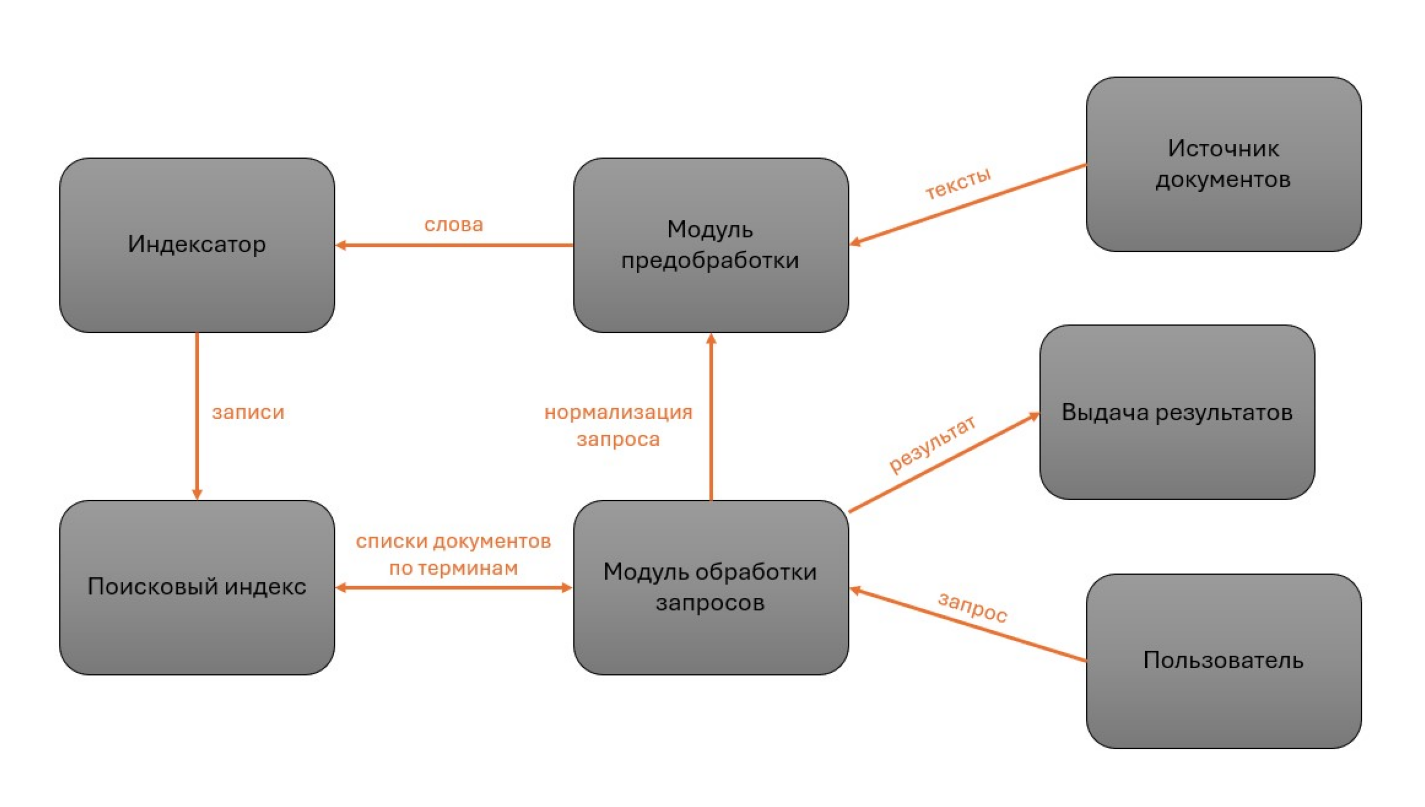

In [8]:
plt.figure(figsize=(12, 8), dpi=150)
img = plt.imread('architecture.jpg')
plt.imshow(img)
plt.axis('off')
plt.show()

**Назначение компонентов:**

| Компонент | Назначение |
|-----------|-----------|
| Источник документов | Хранит исходные тексты и их идентификаторы; поставляет новые документы и выдаёт полный текст по идентификатору |
| Модуль предобработки | Приводит текст к единому виду (регистр, пунктуация, слова, стоп-слова); применяется и к документам, и к запросам, чтобы слова совпадали |
| Индексатор | Строит и обновляет индекс: для каждого слова записывает, в каких документах оно встречается |
| Поисковый индекс | Структура «слово → список документов»; позволяет находить документы без просмотра текстов |
| Модуль обработки запросов | Нормализует запрос, берёт из индекса списки документов, объединяет их по правилам AND/OR |
| Выдача результатов | Формирует ответ пользователю: набор найденных документов и их полные тексты |

## 7. Вывод

Проверим разницу между поиском по индексу и последовательным просмотром.

In [9]:
"""Последовательный просмотр: читаем слова каждого документа."""
def sequential_search(query, mode, docs):
    terms = preprocess(query)
    found, scanned = [], 0
    for doc_id, text in docs.items():
        tokens = preprocess(text)
        scanned += len(tokens)
        present = [t in tokens for t in terms]
        ok = all(present) if (mode == "AND" or len(terms) == 1) else any(present)
        if ok:
            found.append(doc_id)
    return sort_ids(found), scanned


tests = [("давление", "AND"), ("врач", "AND"),
         ("расход вождения", "AND"), ("расход вождения", "OR"),
         ("риск снижает", "AND"), ("риск снижает", "OR")]

rows = []
for q, m in tests:
    by_index = search(q, mode=m, verbose=False)
    by_scan, scanned = sequential_search(q, m, DOCS)
    assert by_index == by_scan, (q, m)
    rows.append({"Запрос": q, "Режим": m, "Результат": fmt(by_index),
                 "Совпадает с просмотром": "да",
                 "Слов просмотрено подряд": scanned,
                 "Обращений к индексу": len(preprocess(q))})

show_table(pd.DataFrame(rows))

Запрос,Режим,Результат,Совпадает с просмотром,Слов просмотрено подряд,Обращений к индексу
давление,AND,"Д4, Д8, Д9",да,225,1
врач,AND,"Д5, Д6, Д7, Д8, Д9",да,225,1
расход вождения,AND,"Д1, Д3",да,225,2
расход вождения,OR,"Д1, Д3, Д4",да,225,2
риск снижает,AND,Д7,да,225,2
риск снижает,OR,"Д2, Д6, Д7, Д8, Д9",да,225,2


### Выводы

**Роль компонентов.** Источник документов хранит исходные тексты. Модуль предобработки приводит тексты и запросы к одному виду, чтобы слова можно было сопоставлять. Индексатор превращает тексты в структуру «слово → список документов». Поисковый индекс хранит эту структуру и позволяет мгновенно получать списки документов. Модуль обработки запросов нормализует запрос, извлекает списки и объединяет их операциями AND (пересечение) и OR (объединение). Выдача результатов возвращает пользователю найденные документы с полным текстом.

**Поиск по индексу и последовательный просмотр.** Результаты обоих способов совпали на всех проверочных запросах, но объём работы разный. При последовательном просмотре на каждый запрос заново читаются и обрабатываются все слова всех документов, так что время растёт вместе с объёмом коллекции. При поиске по индексу тексты не читаются вовсе: достаточно обратиться к записям индекса для слов запроса (в таблице выше 1–2 обращения вместо просмотра 225 слов всех документов), а затраты на разбор текстов выносятся в один раз на этап индексирования. На 9 небольших документах выигрыш невелик, но на больших коллекциях он становится принципиальным. Кроме того, индекс удобно комбинировать операциями над списками (AND/OR).

**Зачем обновлять индекс.** Индекс — это отдельная от документов структура данных, построенная заранее. Новый документ сам по себе в неё не попадает, поэтому поиск его не найдёт, пока индексатор не добавит его идентификатор в записи его слов (и не создаст записи для новых слов). Это показал эксперимент: запрос «давление» вернул Д4, Д8 до добавления Д9 и Д4, Д8, Д9 после. Полная перестройка при этом не нужна — достаточно инкрементально обработать только новый документ.